In [ ]:
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import label_binarize
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd



In [ ]:
# Download latest version
path = kagglehub.dataset_download("zahidmughal2343/global-cancer-patients-2015-2024")

print("Path to dataset files:", path)


Path to dataset files: /kaggle/input/global-cancer-patients-2015-2024


In [ ]:
# Load the dataset
df = pd.read_csv('/kaggle/input/global-cancer-patients-2015-2024/global_cancer_patients_2015_2024.csv')  # Adjust file name as needed
#print(df.shape)
df.head()
#df = df.drop('Patient_ID',axis=1) # not a feature
#print(df.isnull().sum()) # Check for missing values


,Patient_ID,Age,Gender,Country_Region,Year,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Cancer_Type,Cancer_Stage,Treatment_Cost_USD,Survival_Years,Target_Severity_Score
0,PT0000000,71,Male,UK,2021,6.4,2.8,9.5,0.9,8.7,Lung,Stage III,62913.44,5.9,4.92
1,PT0000001,34,Male,China,2021,1.3,4.5,3.7,3.9,6.3,Leukemia,Stage 0,12573.41,4.7,4.65
2,PT0000002,80,Male,Pakistan,2023,7.4,7.9,2.4,4.7,0.1,Breast,Stage II,6984.33,7.1,5.84
3,PT0000003,40,Male,UK,2015,1.7,2.9,4.8,3.5,2.7,Colon,Stage I,67446.25,1.6,3.12
4,PT0000004,43,Female,Brazil,2017,5.1,2.8,2.3,6.7,0.5,Skin,Stage III,77977.12,2.9,3.62


In [ ]:
def bin_severity(score):
    if score <= 3:
        return 0  # Low
    elif score <= 6:
        return 1  # Medium
    else:
        return 2  # High

df['Target_Severity_Score'] = df['Target_Severity_Score'].apply(bin_severity)
print(df['Target_Severity_Score'].value_counts())
df.head()

Target_Severity_Score
1    37536
2     9821
0     2643
Name: count, dtype: int64


,Age,Gender,Country_Region,Year,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Cancer_Type,Cancer_Stage,Treatment_Cost_USD,Survival_Years,Target_Severity_Score
0,71,Male,UK,2021,6.4,2.8,9.5,0.9,8.7,Lung,Stage III,62913.44,5.9,1
1,34,Male,China,2021,1.3,4.5,3.7,3.9,6.3,Leukemia,Stage 0,12573.41,4.7,1
2,80,Male,Pakistan,2023,7.4,7.9,2.4,4.7,0.1,Breast,Stage II,6984.33,7.1,1
3,40,Male,UK,2015,1.7,2.9,4.8,3.5,2.7,Colon,Stage I,67446.25,1.6,1
4,43,Female,Brazil,2017,5.1,2.8,2.3,6.7,0.5,Skin,Stage III,77977.12,2.9,1


<ipython-input-12-775cc5ae1a61>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=target_col, order=df[target_col].value_counts().index, palette='Set2')


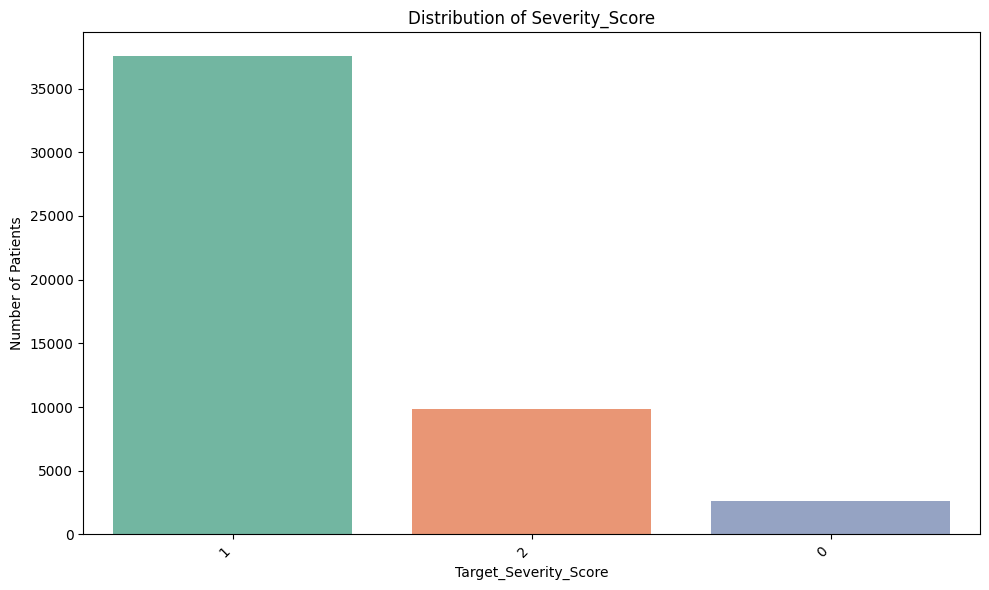

In [ ]:
target_col = 'Target_Severity_Score'
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=target_col, order=df[target_col].value_counts().index, palette='Set2')
plt.title('Distribution of Severity_Score')
plt.xlabel('Target_Severity_Score')
plt.ylabel('Number of Patients')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
def iqr_outlier_filter_by_class(df, label_column, factor=1.2):
    numeric_features = df.select_dtypes(include=['number']).drop(columns=[label_column], errors='ignore')
    outlier_indices = set()

    for label in df[label_column].unique():
        group_df = df[df[label_column] == label]
        for col in numeric_features.columns:
            Q1 = group_df[col].quantile(0.25)
            Q3 = group_df[col].quantile(0.75)
            IQR = Q3 - Q1
            lower = Q1 - factor * IQR
            upper = Q3 + factor * IQR
            outliers = group_df[(group_df[col] < lower) | (group_df[col] > upper)].index
            outlier_indices.update(outliers)

    cleaned_df = df.drop(index=outlier_indices)
    return cleaned_df.reset_index(drop=True), list(outlier_indices)
df_no_outliers, outlier_indices = iqr_outlier_filter_by_class(df, label_column='Target_Severity_Score')
print("Number of outliers removed:", len(outlier_indices))

Number of outliers removed: 1280


In [ ]:


# Define features and target
target = 'Target_Severity_Score'
features = ['Age', 'Genetic_Risk', 'Air_Pollution', 'Alcohol_Use', 'Smoking', 'Obesity_Level', 'Treatment_Cost_USD']
categorical_features = ['Gender', 'Country_Region', 'Cancer_Type', 'Cancer_Stage']



# Split data
X1 = df[features + categorical_features]
y1 = df[target]
X2 = df_no_outliers[features + categorical_features]
y2 = df_no_outliers[target]

# Preprocessor for numeric and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

datasets = {
    "With Outliers": (X1, y1),
    "Without Outliers": (X2, y2)
}

classifiers = {
    'RandomForest': RandomForestClassifier( n_estimators=80, max_depth=8, min_samples_split=2, min_samples_leaf=1,random_state=42),
    'LogisticRegression': LogisticRegression(max_iter=100, random_state=42),
    'DecisionTree': DecisionTreeClassifier(max_depth=None, random_state=42),
    'GradientBoosting': GradientBoostingClassifier( n_estimators=50, random_state=42, subsample=0.8)
}



=== Dataset: With Outliers ===

----- RandomForest -----
Accuracy: 0.829
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.01      0.01       529
           1       0.81      1.00      0.90      7507
           2       1.00      0.40      0.57      1964

    accuracy                           0.83     10000
   macro avg       0.94      0.47      0.49     10000
weighted avg       0.86      0.83      0.79     10000



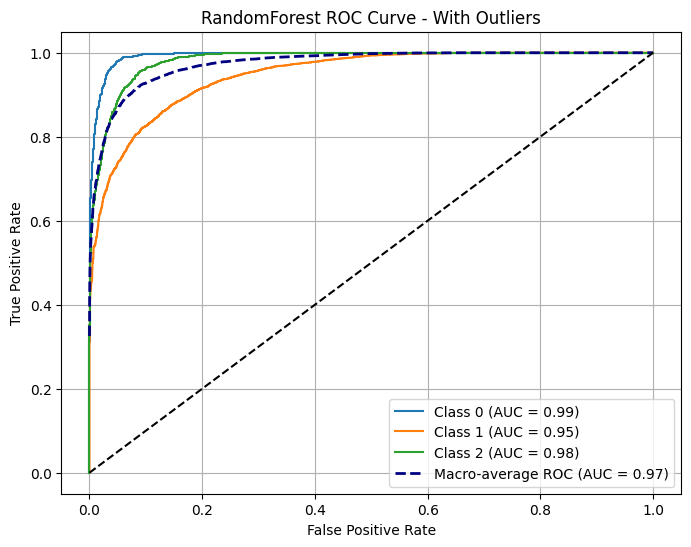

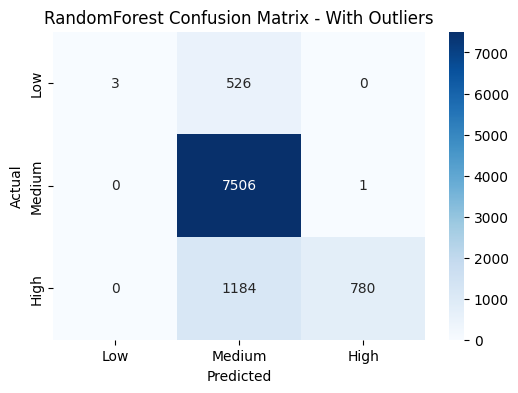


----- LogisticRegression -----


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no pre

Accuracy: 0.793
Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00       529
           1       0.85      0.88      0.86      7507
           2       0.59      0.68      0.63      1964

    accuracy                           0.79     10000
   macro avg       0.48      0.52      0.50     10000
weighted avg       0.76      0.79      0.77     10000



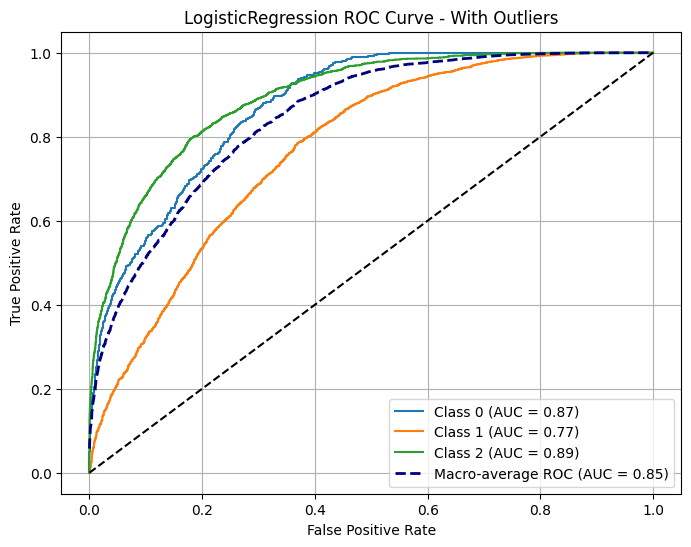

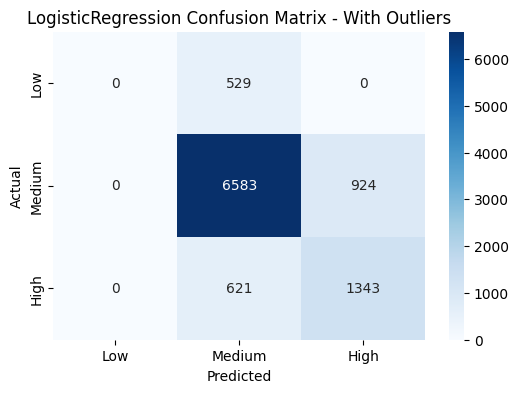


----- DecisionTree -----
Accuracy: 0.896
Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.67      0.72       529
           1       0.92      0.94      0.93      7507
           2       0.81      0.80      0.80      1964

    accuracy                           0.90     10000
   macro avg       0.83      0.80      0.82     10000
weighted avg       0.89      0.90      0.89     10000



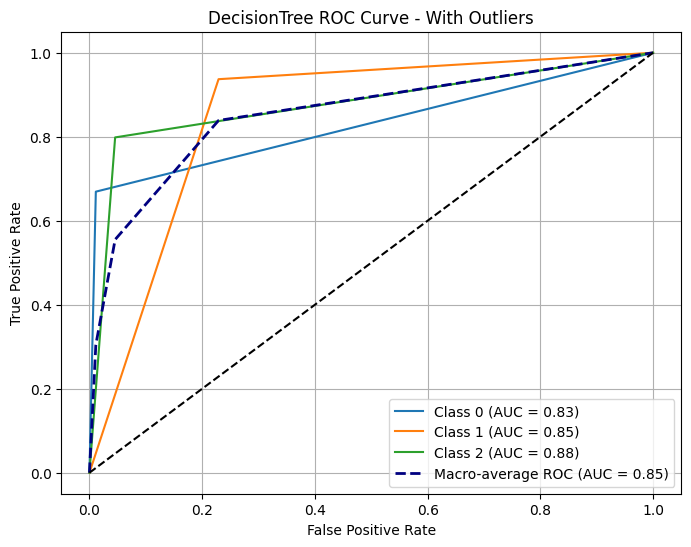

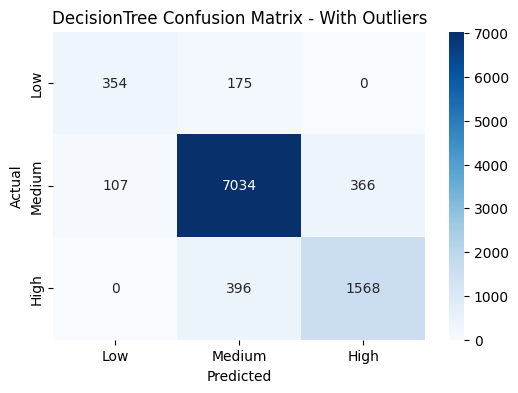


----- GradientBoosting -----
Accuracy: 0.909
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.40      0.57       529
           1       0.89      1.00      0.94      7507
           2       0.98      0.71      0.83      1964

    accuracy                           0.91     10000
   macro avg       0.96      0.70      0.78     10000
weighted avg       0.92      0.91      0.90     10000



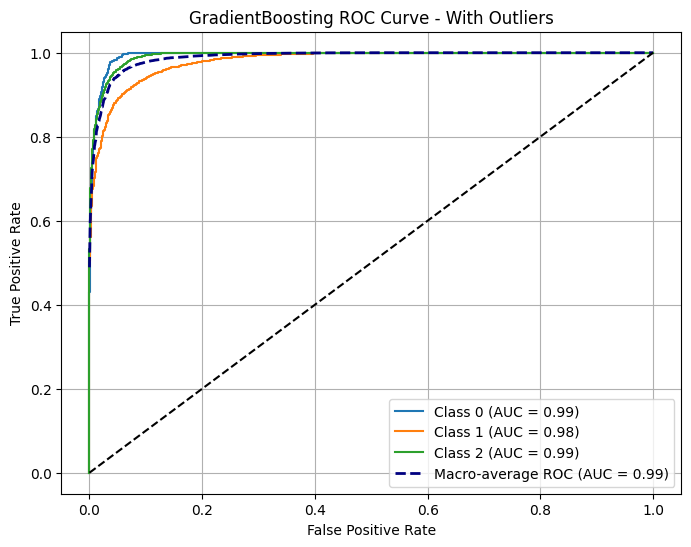

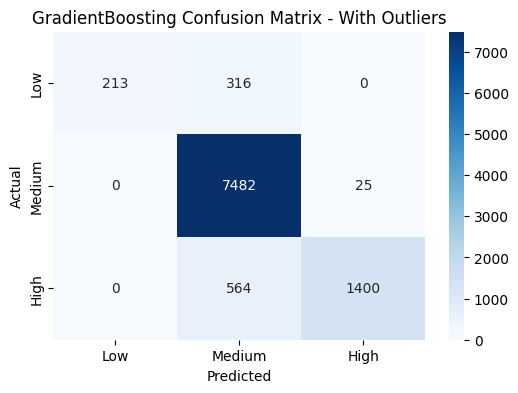


=== Dataset: Without Outliers ===

----- RandomForest -----


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Accuracy: 0.841
Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00       427
           1       0.83      1.00      0.91      7507
           2       1.00      0.38      0.55      1810

    accuracy                           0.84      9744
   macro avg       0.61      0.46      0.48      9744
weighted avg       0.82      0.84      0.80      9744



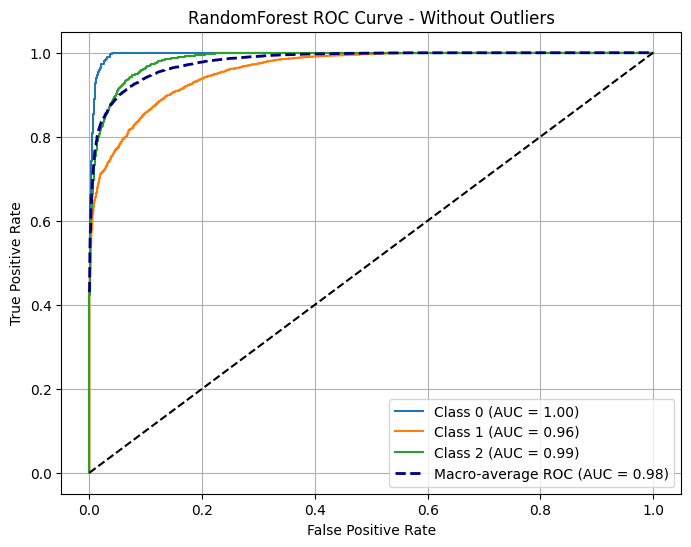

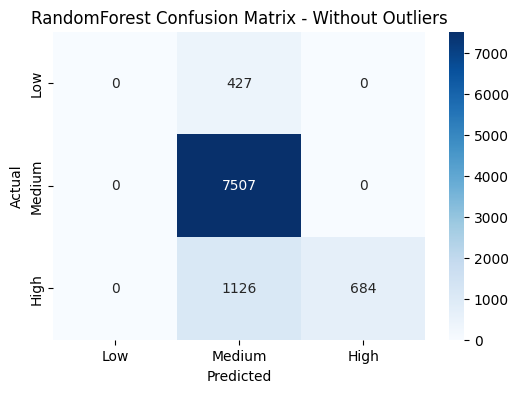


----- LogisticRegression -----


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no pre

Accuracy: 0.809
Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00       427
           1       0.85      0.91      0.88      7507
           2       0.60      0.60      0.60      1810

    accuracy                           0.81      9744
   macro avg       0.49      0.50      0.49      9744
weighted avg       0.77      0.81      0.79      9744



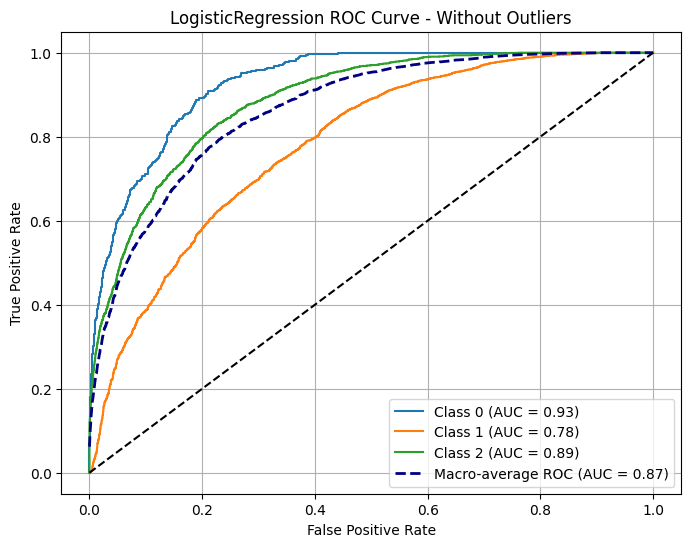

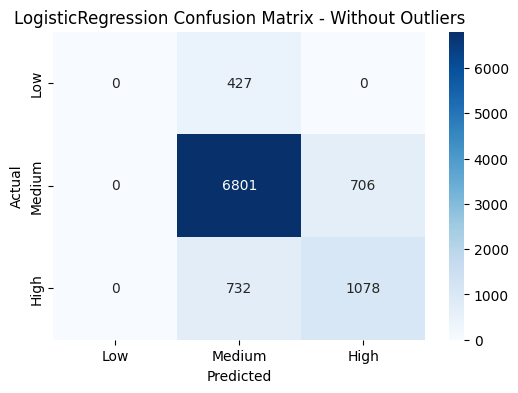


----- DecisionTree -----
Accuracy: 0.915
Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.74      0.75       427
           1       0.94      0.95      0.95      7507
           2       0.83      0.83      0.83      1810

    accuracy                           0.92      9744
   macro avg       0.85      0.84      0.84      9744
weighted avg       0.91      0.92      0.92      9744



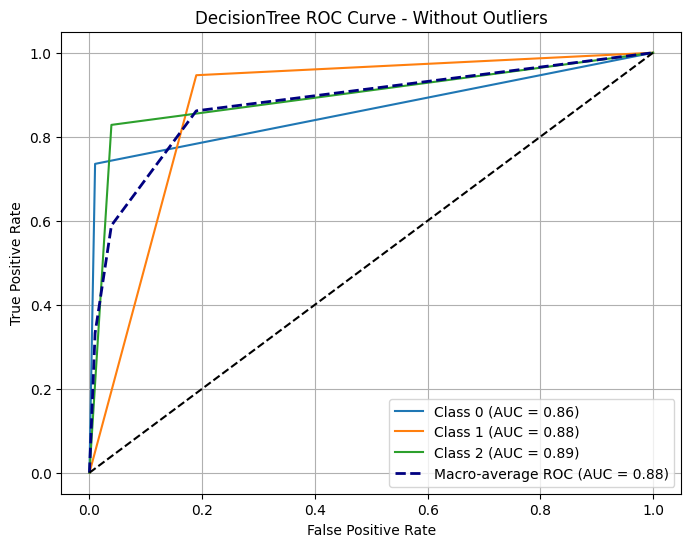

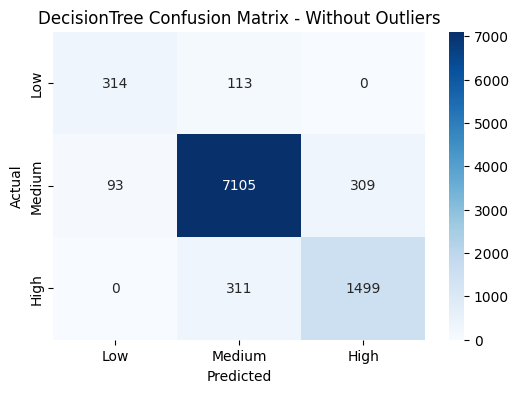


----- GradientBoosting -----
Accuracy: 0.924
Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.47      0.63       427
           1       0.91      1.00      0.95      7507
           2       0.99      0.73      0.84      1810

    accuracy                           0.92      9744
   macro avg       0.96      0.73      0.81      9744
weighted avg       0.93      0.92      0.92      9744



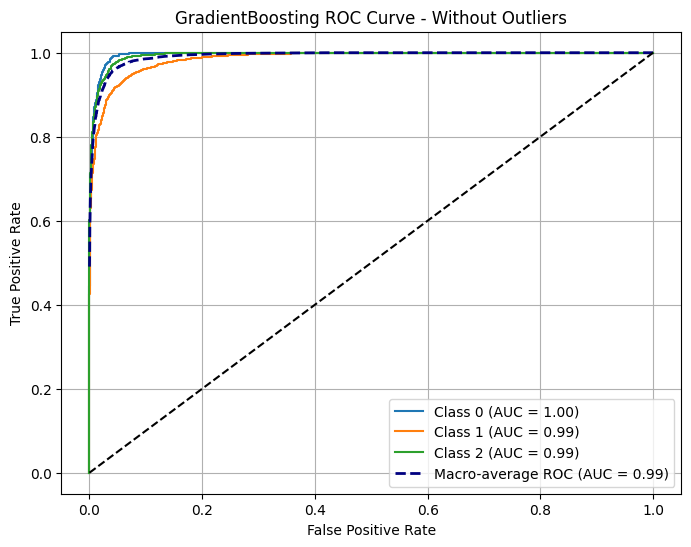

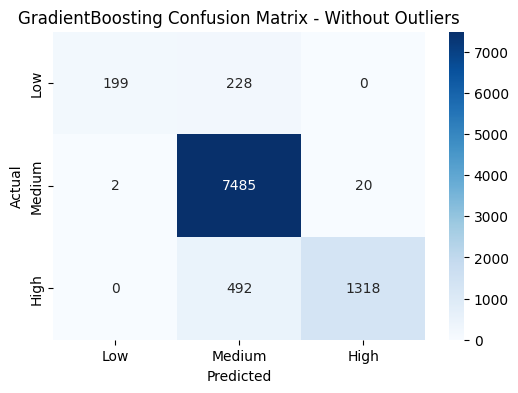

In [ ]:

for dataset_name, (X, y) in datasets.items():
    print(f"\n=== Dataset: {dataset_name} ===")

    # Split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=42
    )

    for name, classifier in classifiers.items():
        print(f"\n----- {name} -----")

        # Build pipeline
        model = Pipeline(steps=[
            ('preprocessor', preprocessor),
            ('classifier', classifier)
        ])

        # Train
        model.fit(X_train, y_train)

        # Predict
        y_pred = model.predict(X_test)

        # Evaluate
        acc = accuracy_score(y_test, y_pred)
        cm = confusion_matrix(y_test, y_pred)
        report = classification_report(y_test, y_pred)

        print(f"Accuracy: {acc:.3f}")
        print("Classification Report:\n", report)

        # roc curve
        if len(np.unique(y_test)) > 2:
            # Binarize labels
            y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
            y_score = model.predict_proba(X_test)

            fpr = dict()
            tpr = dict()
            roc_auc = dict()
            n_classes = y_test_bin.shape[1]

            for i in range(n_classes):
                fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
                roc_auc[i] = auc(fpr[i], tpr[i])

            # Compute macro-average
            all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
            mean_tpr = np.zeros_like(all_fpr)
            for i in range(n_classes):
                mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
            mean_tpr /= n_classes

            fpr["macro"] = all_fpr
            tpr["macro"] = mean_tpr
            roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

            # Plot ROC
            plt.figure(figsize=(8, 6))
            for i in range(n_classes):
                plt.plot(fpr[i], tpr[i], label=f'Class {i} (AUC = {roc_auc[i]:.2f})')

            plt.plot(fpr["macro"], tpr["macro"], color='navy',
                     linestyle='--', linewidth=2,
                     label=f'Macro-average ROC (AUC = {roc_auc["macro"]:.2f})')
            plt.plot([0, 1], [0, 1], 'k--')
            plt.title(f"{name} ROC Curve - {dataset_name}")
            plt.xlabel("False Positive Rate")
            plt.ylabel("True Positive Rate")
            plt.legend(loc="lower right")
            plt.grid(True)
            plt.show()
        # Plot confusion matrix
        plt.figure(figsize=(6,4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=['Low', 'Medium', 'High'],
                    yticklabels=['Low', 'Medium', 'High'])
        plt.title(f"{name} Confusion Matrix - {dataset_name}")
        plt.ylabel('Actual')
        plt.xlabel('Predicted')
        plt.show()

